# 01 · Análisis Exploratorio de Datos

**Prueba Técnica Data Scientist · Ferreycorp** — Modelo de Propensión de Compra

Este notebook no describe el dataset: **produce los parámetros del problema de optimización**
definido en [`docs/brief-problema.md`](../docs/brief-problema.md), y está ordenado según la
matriz de trazabilidad de [`docs/brief-alineamiento-eda.md`](../docs/brief-alineamiento-eda.md).

Cumple a la vez el checklist de la **Fase 1 de
[`docs/brief-metodologia.md`](../docs/brief-metodologia.md)**, que pide seis cosas sobre otro eje:
distribución del objetivo, perfil de clientes, dinámica temporal, estructura de precios, efecto
bruto de la promoción y anomalías. Cuatro de las seis se responden en los bloques A–D; las otras
dos tienen su propia sección (§6), y la §9 verifica los seis ítems contra el código.

Cada sección lleva el identificador del control que satisface (A1–A7, B1–B6, C1–C5, D1–D3, E1–E13)
y cierra con la **consecuencia** del hallazgo. Un gráfico sin consecuencia declarada no entra —
es el criterio de cierre que fija el propio brief de metodología.

La lógica vive en `src/ferreyros/`; aquí solo se orquesta y se interpreta.

| Capa | Módulo |
|---|---|
| Carga, validación, splits | `ferreyros.data` |
| Bloque A · parámetros del objetivo (π, q, λ, m) | `ferreyros.eda.objective` |
| Bloque B · variables de decisión (`y_jtk`, `z_jt`, `x_ijt`) | `ferreyros.eda.decisions` |
| Bloque C · cotas de las restricciones (R3–R8) | `ferreyros.eda.constraints` |
| Bloque D · demografía y segmentación M0 | `ferreyros.eda.segments` |
| Dinámica temporal (estacionalidad, tendencia, arranque) | `ferreyros.eda.dynamics` |
| Anomalías (coherencia, colas, clientes atípicos) | `ferreyros.eda.anomalies` |
| Variables derivadas | `ferreyros.features` |
| Celda de control y auditoría | `ferreyros.audit` |
| Figuras | `ferreyros.plots` |

In [1]:
import sys
from pathlib import Path

# Permite ejecutar el notebook sin instalar el paquete (uv run jupyter / VS Code).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from ferreyros import audit, config as cfg, data, features, plots
from ferreyros.eda import anomalies, constraints, decisions, dynamics, objective, segments

plots.set_style()
pd.set_option("display.max_columns", 60, "display.width", 180)

print("raíz del proyecto:", ROOT)

raíz del proyecto: /Users/jessieblake/Developer/Projects/Ferreyros


---
## 0 · Celda de control

Antes de analizar nada, reproducir las cifras de referencia de la §4 del brief de alineamiento.
Si alguna no cuadra, hay un error de carga, filtro o agregación — y conviene saberlo **ahora**,
no después de haber entrenado un modelo sobre datos mal leídos.

In [2]:
df = data.load_raw()
control = audit.control_cell(df)

print(f"Cifras verificadas: {len(control)}  |  discrepancias: {control.attrs['n_fallas']}")
assert control.attrs["all_ok"], control[control["veredicto"] != "OK"]
control

Cifras verificadas: 44  |  discrepancias: 0


,cifra,observado,esperado,veredicto
0,n_rows,58693.0000,58693.0000,OK
1,n_cols,24.0000,24.0000,OK
2,n_clients,500.0000,500.0000,OK
3,n_days,730.0000,730.0000,OK
4,day_min,1.0000,1.0000,OK
5,day_max,730.0000,730.0000,OK
6,n_nulls,0.0000,0.0000,OK
7,n_duplicates,0.0000,0.0000,OK
8,purchase_rate,0.2494,0.2494,OK
9,n_purchases,14638.0000,14638.0000,OK


**Consecuencia:** las 44 cifras cuadran. El dataset cargado es el mismo sobre el que se
escribieron los briefs, así que todo lo que sigue es comparable con ellos.

---
## 1 · Estructura del dataset y contrato de datos

Controles **E1, E4, E5, E7, E11** y **D2**.

In [3]:
print(data.load_data_dictionary())

-id : Codigo del cliente
-dia_visita : Número de día de la visita contando desde 0 (apertura de la tienda)
-incidencia_compra : 0 si no compró durante la visita, 1 si compró algo
-id_marca :  identificador de la marca
-cantidad : Cantidad comprada
-Ultima_marca_comprada : Ultima marca comprada
-ultima_cantidad_comprada : ultima_cantidad_comprada
-precio_marca_x : precio de la marca x
-promo_marca_x :  Si la marca esta en promoción ese día
-genero : genero del cliente 
-estado_civil : estado civil del cliente
-edad : edad del cliente
-nivel_educacion : nivel_educacion del cliente
-ingreso_anual : ingreso anual del cliente
-ocupacion : ocupacion del cliente
-tamanio_ciudad : NO CONSIDERAR ESTA VARIABLE 


In [4]:
data.dataset_overview(df).to_frame("valor")

,valor
filas,58693.0000
columnas,24.0000
clientes_unicos,500.0000
dias_distintos,730.0000
dia_min,1.0000
dia_max,730.0000
visitas_por_cliente_media,117.4000
visitas_por_cliente_min,72.0000
visitas_por_cliente_max,358.0000
visitas_por_dia_media,80.4000


Panel longitudinal: **500 clientes** observados ~117 veces cada uno durante **730 días**.
La unidad de generalización es el cliente, no la fila — esto determina toda la validación.

In [5]:
# La columna `rol` es lo que vuelve esta tabla un artefacto de alineamiento y no un df.info():
# declara para qué sirve cada columna dentro del problema de optimización.
data.schema_profile(df)

,dtype,n_unique,n_nulos,min,max,rol
id,int64,500,0,2.000000e+08,2.000005e+08,clave de cliente (agrupacion)
dia_visita,int64,730,0,1.000000e+00,7.300000e+02,eje temporal (split)
incidencia_compra,int64,2,0,0.000000e+00,1.000000e+00,TARGET M1 (pi)
id_marca,int64,6,0,0.000000e+00,5.000000e+00,TARGET M2 (q) - post-resultado
cantidad,int64,16,0,0.000000e+00,1.500000e+01,TARGET M3 (lambda) - post-resultado
ultima_marca_comprada,int64,6,0,0.000000e+00,5.000000e+00,feature historial (lag verificado)
ultima_cantidad_comprada,int64,2,0,0.000000e+00,1.000000e+00,"feature historial (binaria, mal nombrada)"
precio_marca_1,float64,37,0,1.100000e+00,1.590000e+00,variable de decision y_jtk (precio)
precio_marca_2,float64,30,0,1.260000e+00,1.900000e+00,variable de decision y_jtk (precio)
precio_marca_3,float64,21,0,1.870000e+00,2.140000e+00,variable de decision y_jtk (precio)


In [6]:
# E11 · consistencia lógica entre target y resultados
data.consistency_checks(df)

,verificacion,violaciones,estado
0,compra=1 & cantidad=0,0,OK
1,compra=1 & id_marca=0,0,OK
2,compra=0 & cantidad>0,0,OK
3,compra=0 & id_marca>0,0,OK
4,id_marca fuera de 0-5,0,OK
5,cantidad negativa,0,OK
6,precio <= 0,0,OK
7,promo fuera de 0/1,0,OK


In [7]:
# D2 · la demografía debe ser invariante dentro de cada cliente
data.static_demographics_check(df)

,variable,clientes_con_mas_de_un_valor,estado
0,genero,0,estatica
1,estado_civil,0,estatica
2,edad,0,estatica
3,nivel_educacion,0,estatica
4,ingreso_anual,0,estatica
5,ocupacion,0,estatica


**Consecuencia:** cero violaciones y demografía estática. Se puede agregar a nivel cliente
sin perder información, lo que habilita la matriz de segmentación del modelo M0.

### 1.1 · Qué son realmente las columnas `ultima_*` (E4, E5)

El diccionario dice que `ultima_cantidad_comprada` es una cantidad. No lo es.
Verificamos ambas columnas contra el lag verdadero en lugar de confiar en el nombre.

In [8]:
data.verify_lag_columns(df)

,verificacion,coincidencia,conclusion
0,ultima_marca_comprada == shift(1) de id_marca ...,1.0000,"lag real, usable sin fuga"
1,ultima_marca_comprada == id_marca de la misma ...,0.6851,coincidencia parcial esperada (no es copia de ...
2,ultima_cantidad_comprada tiene 2 valores disti...,2.0000,binaria: el diccionario la nombra mal
3,ultima_cantidad_comprada == shift(1) de incide...,1.0000,"es el lag del indicador de compra, no una cant..."


**Consecuencia, dos hallazgos:**

1. `ultima_marca_comprada` **sí** es la marca de la visita anterior (coincidencia 1.0 con
   `shift(1)` por cliente). Es usable como feature sin fuga de datos.
2. `ultima_cantidad_comprada` es **binaria**: es el lag del indicador de compra, no una
   cantidad. El diccionario la nombra mal. Se usa con su significado real y se documenta;
   si se necesita la cantidad rezagada real, hay que construirla.

In [9]:
# E7 · `ultima_marca_comprada == 0` es ausencia de historial, no un nulo
data.no_history_profile(df).to_frame("valor")

,valor
filas_sin_historial,44133.0000
pct_sin_historial,75.2000
de_ellas_primera_visita,500.0000
tasa_compra_sin_historial,0.1967
tasa_compra_con_historial,0.4091


**Consecuencia:** las 44,133 filas sin historial **no se imputan**. La diferencia de tasa de
compra entre tener y no tener historial es señal real, y la moda la destruiría.

---
## 2 · Bloque A — Parámetros de la función objetivo

El objetivo del problema es

$$\max \sum_{i,j,t} x_{ijt}\; \pi_{it} \; q_{ijt} \; \lambda_{ijt} \; m_{jk}$$

Esta sección estima la forma empírica de cada factor: **π** (A1–A3), **q** (A4–A5),
**λ** (A6) y **m** (A7).

### A1 · π — tasa base y estabilidad temporal

In [10]:
objective.purchase_rate(df).to_frame("valor")

,valor
visitas,58693.0000
compras,14638.0000
tasa_compra,0.2494
accuracy_de_predecir_siempre_no_compra,0.7506


,periodo,visitas,clientes,tasa_compra,desvio_vs_global
0,T1 (d1-182),16535,500,0.2333,-0.0161
1,T2 (d183-365),14545,500,0.2546,0.0052
2,T3 (d366-547),14143,500,0.2632,0.0138
3,T4 (d548-730),13470,500,0.2491,-0.0003


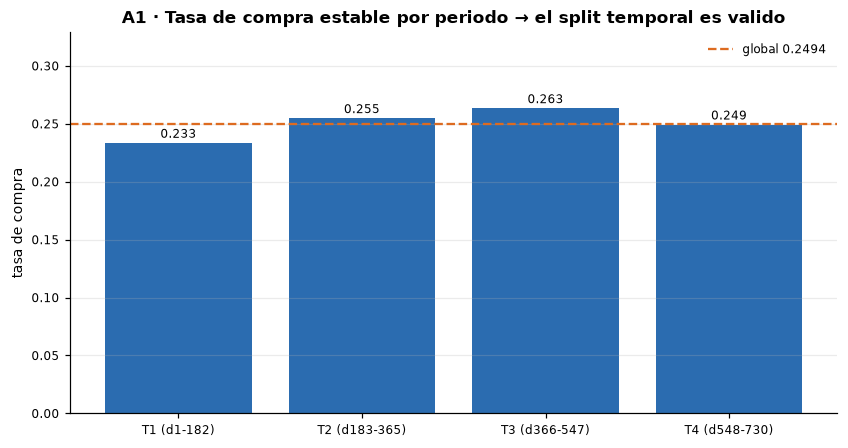

In [11]:
by_period = objective.purchase_rate_by_period(df)
display(by_period)

fig, ax = plt.subplots()
plots.plot_rate_stability(by_period, df[cfg.TARGET_INCIDENCE].mean(), ax=ax)
plt.show()

**Consecuencia:** la tasa base es **24.94%** y se mantiene entre 23.4% y 26.3% a lo largo de
los cuatro semestres. No hay drift estructural, así que el split temporal es válido y train/test
son comparables.

Nótese también que predecir siempre "no compra" da **75.1% de accuracy**. Por eso la métrica
principal es PR-AUC y no accuracy: el número alto esconde un modelo sin valor.

### A2 · π — sensibilidad al precio

,quintil_precio_min,visitas,precio_min_medio,tasa_compra
0,"(1.0990000000000002, 1.33]",13829,1.261,0.2827
1,"(1.33, 1.35]",9831,1.347,0.2475
2,"(1.35, 1.42]",12926,1.394,0.2530
3,"(1.42, 1.48]",12752,1.470,0.2531
4,"(1.48, 1.59]",9355,1.506,0.1922


La incidencia cae de 0.2827 a 0.1922 entre el quintil mas barato y el mas caro: 32.0% de caida relativa.


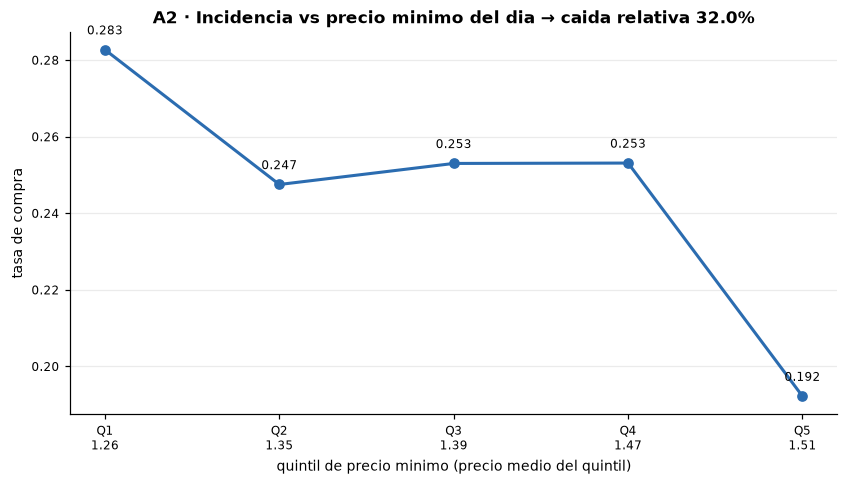

In [12]:
by_price = objective.incidence_by_price_quintile(df)
display(by_price)
print(by_price.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_price_elasticity(by_price, ax=ax)
plt.show()

In [13]:
# Sensibilidad al precio propio de cada marca, sobre su propia distribución
objective.incidence_by_brand_price_quintile(df)

,marca,precio_q1,precio_q_ultimo,tasa_q1,tasa_q_ultimo,caida_relativa_pct
0,1,1.261,1.506,0.2804,0.1922,31.5
1,2,1.496,1.900,0.2987,0.2270,24.0
2,3,1.947,2.079,0.2571,0.2419,5.9
3,4,2.014,2.260,0.2308,0.2505,-8.5
4,5,2.516,2.769,0.2671,0.2513,5.9


**Consecuencia:** hay elasticidad que estimar. La incidencia cae un **32% relativo** entre el
quintil de precio más bajo y el más alto. Si esta señal no existiera, la variable de decisión
de precio `y_jtk` no tendría nada contra lo que optimizar.

### A3 · π — sensibilidad a la promoción

,n_promos_dia,visitas,tasa_compra,lift_vs_sin_promo
0,0,22748,0.2184,1.000
1,1,24040,0.2599,1.190
2,2,9516,0.2901,1.328
3,3,2389,0.2767,1.267


El efecto no es monotono: crece hasta 2 marcas en promocion y luego cae. Promocionar mas no es promocionar mejor.


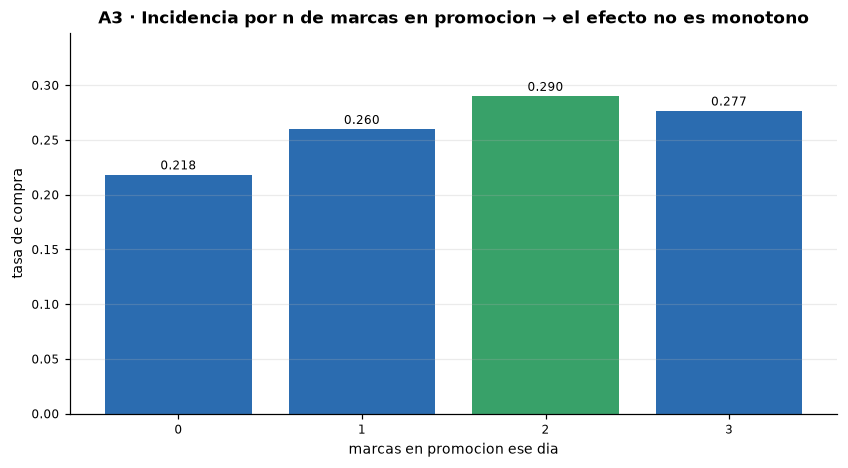

In [14]:
by_promo = objective.incidence_by_n_promos(df)
display(by_promo)
print(by_promo.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_promo_incidence(by_promo, ax=ax)
plt.show()

**Consecuencia:** la incidencia sube de 21.8% sin promoción a 29.0% con dos marcas en promoción,
y luego **cae** con tres. El efecto no es monótono: promocionar más no es promocionar mejor.
La restricción R5 (tope de días de promoción) tiene sentido económico, no solo presupuestario.

### A3b · π — efecto bruto de la promoción, marca por marca

,marca,dias_promo,visitas_con_promo,tasa_con_promo,tasa_sin_promo,delta_pp,lift,z,efecto
0,1,235,20181,0.2702,0.2385,3.16,1.133,8.31,expande el mercado
1,2,222,18524,0.2763,0.2370,3.93,1.166,10.05,expande el mercado
2,3,29,2512,0.2556,0.2491,0.64,1.026,0.73,no distinguible del ruido
3,4,80,6917,0.2711,0.2465,2.46,1.100,4.33,expande el mercado
4,5,24,2105,0.3159,0.2469,6.90,1.279,6.70,expande el mercado


4 de 5 marcas mueven la incidencia por encima del ruido (marcas 1, 2, 4, 5). El resto redistribuye share sin crear compras: su descuento se paga con unidades que se habrian vendido igual. La funcion objetivo necesita las dos lecturas, porque el termino de promocion resta costo siempre y suma ingreso solo si hay compra incremental.


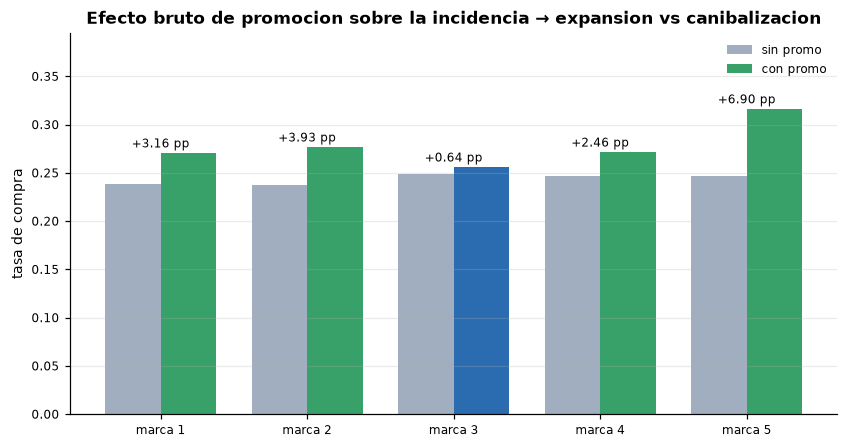

In [15]:
promo_inc = objective.incidence_by_promo_per_brand(df)
display(promo_inc)
print(promo_inc.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_promo_incidence_by_brand(promo_inc, ax=ax)
plt.show()

**Consecuencia — y esto matiza el hallazgo central del EDA:** A5 (más abajo) mide si el descuento
mueve el **share** condicional a que haya compra, que es canibalización entre marcas. Esta tabla
mide algo distinto: si el descuento hace que la compra **ocurra**, que es expansión de mercado.
Son dos términos separados de la función objetivo —la promoción resta costo siempre y suma
ingreso solo si hay compra incremental— y **no coinciden**:

| Marca | Días en promo | Δ incidencia | z | Lift del share (A5) | Lectura |
|---|---|---|---|---|---|
| 1 | 235 | +3.16 pp | 8.3 | ×1.08 | expande, pero ya se promociona un tercio de los días |
| 2 | 222 | +3.93 pp | 10.1 | ×1.39 | expande, ya se promociona un tercio de los días |
| 3 | 29 | +0.64 pp | **0.7** | ×1.86 | **solo redistribuye**: su lift de share no crea compras |
| 4 | 80 | +2.46 pp | 4.3 | ×1.16 | expande moderadamente |
| 5 | 24 | **+6.90 pp** | 6.7 | ×1.66 | **el arbitraje real** |

La marca 5 es el caso nítido: **24 días** de promoción en 730, el **mayor** efecto incremental
sobre la incidencia (+6.90 pp, ×1.28) y el 35.8% del ingreso. La marca 3, que por lift de share
parecía la más elástica (×1.86), **no mueve la incidencia** (z=0.7): su descuento se paga con
compras que habrían ocurrido igual. P2 debe optimizar contra el efecto incremental, no contra el
lift de share — distinguirlos es lo que evita comprar volumen ya vendido.

### A4 · q — elección de marca condicional a compra

,id_marca,compras,unidades,precio_pagado_medio,cantidad_media,ingreso,share_compras_pct,share_ingreso_pct
0,1,1350,4717,1.34,3.49,6305.65,9.2,7.6
1,2,4542,12828,1.71,2.82,21768.31,31.0,26.3
2,3,841,2994,2.01,3.56,6021.52,5.7,7.3
3,4,2927,8877,2.15,3.03,19040.10,20.0,23.0
4,5,4978,11198,2.64,2.25,29621.00,34.0,35.8


Condicional a compra: 14,638 filas de 58,693. Este es el universo de entrenamiento de M2 y M3 (control E12).


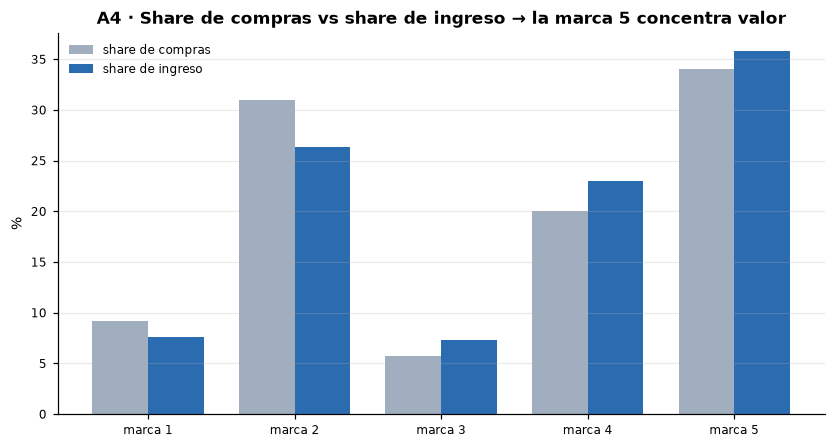

In [16]:
shares = objective.brand_share(df)
display(shares)
print(shares.attrs["universo"])

fig, ax = plt.subplots()
plots.plot_brand_share(shares, ax=ax)
plt.show()

**Consecuencia:** el universo de M2 y M3 son las **14,638 compras**, no las 58,693 visitas
(control E12). La marca 5 es premium y concentra el **35.8% del ingreso** con solo el 34% de
las compras; la marca 1 aporta 7.6%.

### A5 · q — sustitución, canibalización y el hallazgo central

,marca,frecuencia_promo,share_con_promo,share_sin_promo,lift,respuesta_vs_inversion
0,1,0.3438,0.097,0.090,1.08,"SOBRE-PROMOCIONADA (baja respuesta, alta inver..."
1,2,0.3156,0.380,0.273,1.39,alineada
2,3,0.0428,0.103,0.055,1.86,"SUB-PROMOCIONADA (alta respuesta, baja inversion)"
3,4,0.1179,0.227,0.196,1.16,alineada
4,5,0.0359,0.549,0.330,1.66,"SUB-PROMOCIONADA (alta respuesta, baja inversion)"


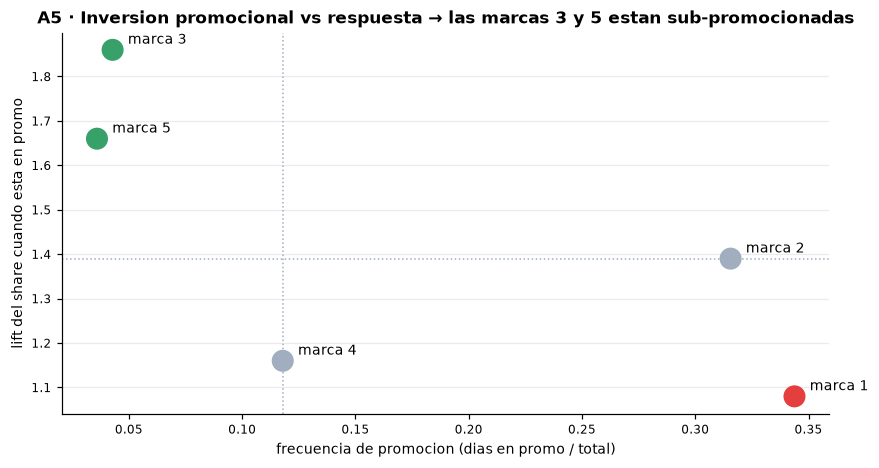

In [17]:
lift = objective.promo_lift_on_brand_share(df)
display(lift)

fig, ax = plt.subplots()
plots.plot_promo_lift(lift, ax=ax)
plt.show()

**Consecuencia — este es el hallazgo central del EDA:** las marcas que **menos** se promocionan
son las que **más** responden.

| Marca | Frecuencia de promo | Lift del share | Diagnóstico |
|---|---|---|---|
| 1 | 34.4% | ×1.08 | sobre-promocionada |
| 2 | 31.6% | ×1.39 | sobre-promocionada |
| 3 | 4.3% | **×1.86** | **sub-promocionada** |
| 5 | 3.6% | **×1.66** | **sub-promocionada** |

El descuento está concentrado donde menos valor se captura. Esta es la primera hipótesis de
arbitraje que el sub-problema **P2** (calendario promocional) debe cuantificar.

marca_actual,1,2,3,4,5
marca_anterior,,,,,
1,0.617,0.229,0.018,0.065,0.072
2,0.074,0.736,0.020,0.068,0.102
3,0.085,0.045,0.806,0.008,0.057
4,0.036,0.080,0.006,0.780,0.098
5,0.016,0.053,0.009,0.058,0.864


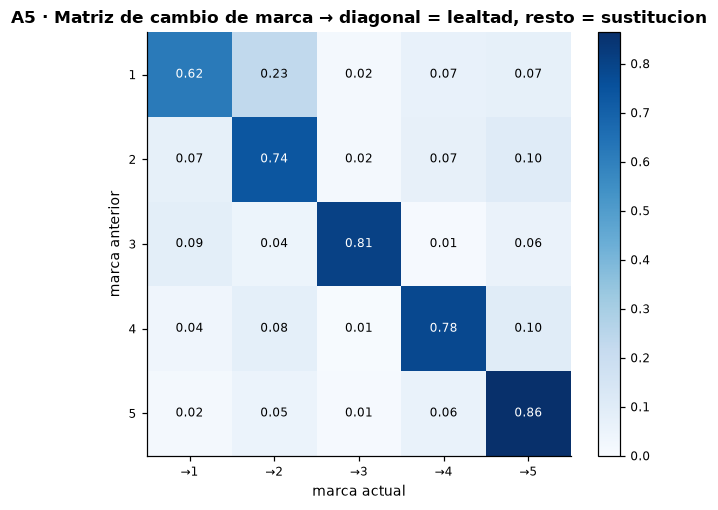

In [18]:
switch = objective.brand_switching_matrix(df)
display(switch)

fig, ax = plt.subplots(figsize=(6.5, 5))
plots.plot_switching_matrix(switch, ax=ax)
plt.show()

**Consecuencia:** la diagonal mide lealtad y el resto sustitución. Son los patrones que las
elasticidades cruzadas del modelo M2 deben reproducir; si M2 no los recupera, está mal
especificado.

### A6 · λ — cantidad esperada dado que compra

,cantidad,compras,pct,pct_acumulado
0,1,3542,24.2,24.2
1,2,3800,26.0,50.2
2,3,4241,29.0,79.2
3,4,1165,8.0,87.2
4,5,921,6.3,93.5
5,6,355,2.4,95.9
6,7,200,1.4,97.3
7,8,133,0.9,98.2
8,9,106,0.7,98.9
9,10,81,0.6,99.5


resumen: {'count': 14638.0, 'mean': 2.77, 'std': 1.8, 'min': 1.0, '25%': 2.0, '50%': 2.0, '75%': 3.0, 'max': 15.0}


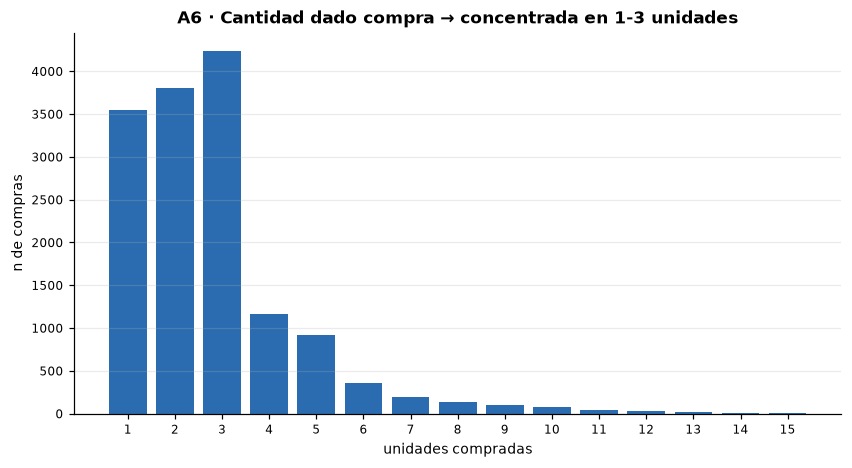

In [19]:
qty = objective.quantity_distribution(df)
display(qty.head(10))
print("resumen:", qty.attrs["resumen"])

fig, ax = plt.subplots()
plots.plot_quantity_distribution(qty, ax=ax)
plt.show()

In [20]:
objective.quantity_summary_by_brand(df)

,id_marca,compras,media,mediana,p90,maximo
0,1,1350,3.49,3.0,6.0,14
1,2,4542,2.82,3.0,5.0,13
2,3,841,3.56,3.0,6.0,14
3,4,2927,3.03,3.0,5.0,13
4,5,4978,2.25,2.0,4.0,15


**Consecuencia:** media de **2.77 unidades**, concentrada en 1–3 (≈79% de las compras) con cola
hasta 15. Es una distribución de conteo asimétrica: M3 debe ser un modelo de conteo (Poisson /
binomial negativa) o una regresión sobre log, no una lineal ordinaria.

### A7 · m — ingreso observado y la brecha de costos

In [21]:
revenue = objective.revenue_by_brand(df)
display(revenue)
print("ingreso total:", revenue.attrs["ingreso_total"])
print(revenue.attrs["brecha"])

,id_marca,unidades,ingreso,precio_medio,share_ingreso_pct,margen_unitario
0,1,4717,6305.65,1.34,7.6,REQUIERE SUPUESTO (c_j no esta en el dato)
1,2,12828,21768.31,1.71,26.3,REQUIERE SUPUESTO (c_j no esta en el dato)
2,3,2994,6021.52,2.01,7.3,REQUIERE SUPUESTO (c_j no esta en el dato)
3,4,8877,19040.10,2.15,23.0,REQUIERE SUPUESTO (c_j no esta en el dato)
4,5,11198,29621.00,2.64,35.8,REQUIERE SUPUESTO (c_j no esta en el dato)


ingreso total: 82756.58
El margen m_jk = p_jk - c_j no es calculable: el dataset no contiene costos. La optimizacion se entrega con analisis de sensibilidad sobre c_j (control C2).


In [22]:
# Declarar lo que el dato no puede dar es un criterio de aceptación, no una excusa
objective.missing_business_parameters()

,parametro,descripcion,esta_en_el_dato,tratamiento
0,c_j,Costo unitario por marca,No,Supuesto de margen bruto % por marca + sensibi...
1,a,Costo de contacto / impulso comercial,No,Supuesto; define el umbral de decision de P1
2,d_j,Costo de un periodo de promocion,No,Supuesto; acota el calendario de P2
3,B,Presupuesto de ejecucion,No,Input de negocio; restriccion R2
4,F_i,Tope de contactos por cliente,Parcial,Acotable con la frecuencia de visita observada
5,Cap_jt,Capacidad / inventario por marca,Parcial,Acotable con unidades/dia observadas
6,rho,Margen porcentual minimo,No,Politica comercial; restriccion R6


**Consecuencia:** el margen `m_jk = p_jk − c_j` **no es calculable**: no hay costos en el
dataset. La optimización se entrega con análisis de sensibilidad sobre `c_j`, y el valor de la
solución está en la **política de decisión**, que es robusta al nivel exacto del costo, no en
una cifra absoluta de margen.

---
## 3 · Bloque B — Variables de decisión

`y_jtk` (precio), `z_jt` (promoción) y `x_ijt` (targeting).

### B1 · `y_jtk` — la escalera de precios discreta

,marca,n_puntos_precio,precio_min,precio_max,precio_medio,rango_relativo_pct,paso_mediano
0,1,37,1.10,1.59,1.39,44.5,0.01
1,2,30,1.26,1.90,1.78,50.8,0.01
2,3,21,1.87,2.14,2.01,14.4,0.01
3,4,26,1.76,2.26,2.16,28.4,0.01
4,5,44,2.11,2.80,2.65,32.7,0.01


El espacio de decision de precio es finito: 37 x 30 x 21 x 26 x 44 combinaciones por periodo. Discretizar permite precalcular pi, q y lambda por escenario y resolver un MILP.


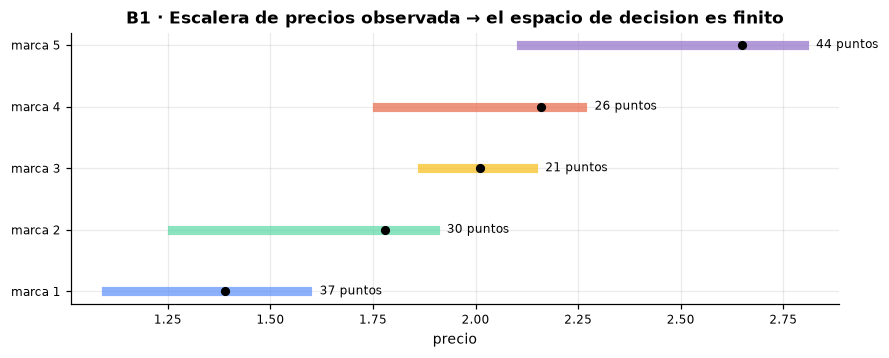

In [23]:
ladder = decisions.price_ladder(df)
display(ladder)
print(ladder.attrs["lectura"])

fig, ax = plt.subplots(figsize=(9, 3.2))
plots.plot_price_ladder(ladder, ax=ax)
plt.show()

**Consecuencia — la decisión de modelado más importante:** el precio no es continuo, es un
**menú finito de 21 a 44 puntos ya observados** por marca. Al discretizar, π, q y λ se
precalculan por escenario y el MINLP se convierte en un **MILP** resoluble con solvers estándar.

### B2 · `y_jtk` — dinámica de precios y arquitectura de marcas

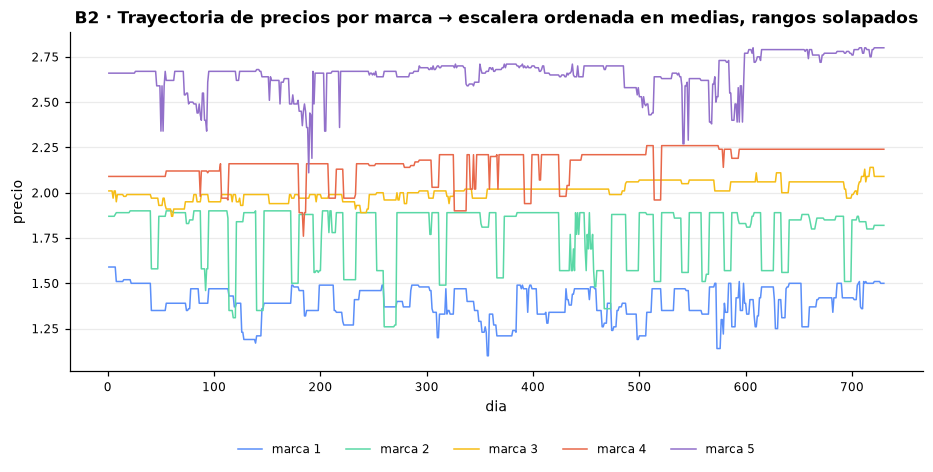

In [24]:
daily = decisions.daily_price_series(df)

fig, ax = plt.subplots(figsize=(10, 4))
plots.plot_price_series(daily, ax=ax)
plt.show()

In [25]:
decisions.price_correlation(df)

,precio_marca_1,precio_marca_2,precio_marca_3,precio_marca_4,precio_marca_5
precio_marca_1,1.000,0.098,0.024,-0.139,0.071
precio_marca_2,0.098,1.000,-0.004,-0.010,-0.033
precio_marca_3,0.024,-0.004,1.000,0.447,0.229
precio_marca_4,-0.139,-0.010,0.447,1.000,0.202
precio_marca_5,0.071,-0.033,0.229,0.202,1.000


In [26]:
overlap = decisions.price_overlap_check(df)
display(overlap)
print(overlap.attrs["lectura"])

,par,max_marca_inferior,min_marca_superior,se_solapan,medias_ordenadas
0,marca 1 vs marca 2,1.59,1.26,True,True
1,marca 2 vs marca 3,1.90,1.87,True,True
2,marca 3 vs marca 4,2.14,1.76,True,True
3,marca 4 vs marca 5,2.26,2.11,True,True


Las medias estan ordenadas pero los rangos se solapan. El ordenamiento estricto de precios (R7) es una decision de modelado para proteger el posicionamiento, no un hecho del dato: se implementa activable y se reporta su costo.


**Consecuencia (control C3):** las medias de precio están ordenadas (1.34 → 2.64) pero los
**rangos se solapan** — la marca 4 baja a 1.76, por debajo del mínimo de la marca 3. Por lo
tanto la restricción R7 (ordenamiento estricto de precios) es una **decisión de modelado** para
proteger el posicionamiento, no un hecho del dato: se implementa activable y se reporta el costo
de imponerla.

### B2b · `y_jtk` — brecha de precio relativo

,marca,precio_medio,precio_relativo_medio,precio_relativo_min,precio_relativo_max,desvio_std_relativo,brecha_vs_mas_barata,pct_dias_mas_barata
0,1,1.393,0.696,0.561,0.781,0.0420,0.003,96.6
1,2,1.781,0.889,0.669,0.993,0.0731,0.391,3.4
2,3,2.009,1.004,0.938,1.076,0.0269,0.619,0.0
3,4,2.164,1.082,0.924,1.176,0.0413,0.773,0.0
4,5,2.658,1.328,1.114,1.427,0.0447,1.267,0.0


La marca 1 es la mas barata el 96.6% de los dias y la marca 2 es la que mueve mas su posicion relativa (desvio 0.0731). La dispersion media del precio relativo es 0.0456: las brechas se mueven, asi que hay palanca de precio que optimizar y variacion suficiente para identificar elasticidades.


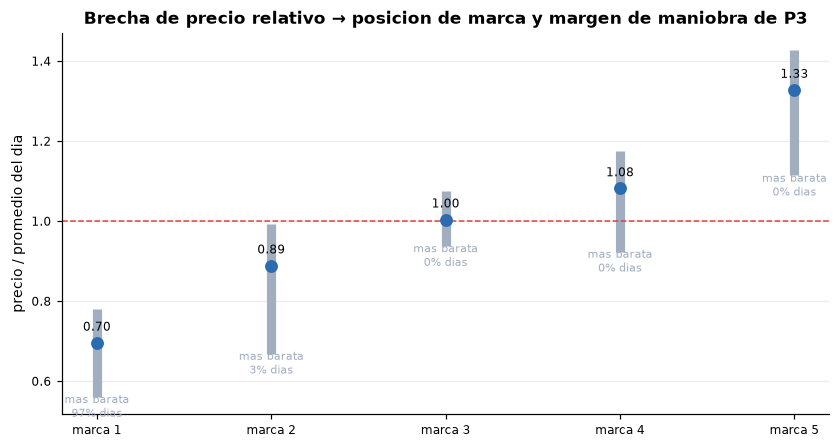

In [27]:
gap = decisions.relative_price_gap(df)
display(gap)
print(gap.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_relative_price_gap(gap, ax=ax)
plt.show()

**Consecuencia:** el precio absoluto de una marca dice poco, porque las cinco se mueven; lo que
el cliente ve es la **brecha**. De esta tabla salen dos lecturas, y las dos tienen consecuencia:

- **Nivel.** El precio relativo medio ordena las marcas de **0.70 a 1.33** y la marca 1 es la más
  barata el **96.6% de los días**. Ese es el posicionamiento que codifica la feature
  `precio_relativo_j`, y es invariante a la escala — a diferencia del precio absoluto, que en test
  sale del rango de train (el 79.6% de las filas para la marca 5).
- **Dispersión.** Las brechas se mueven: desvío medio **0.046**, y la marca 2 llega a 0.073. Si
  estuvieran congeladas no habría palanca de precio que optimizar en P3, **ni** variación
  suficiente para identificar elasticidades a partir de dato observacional. Que se muevan es lo
  que vuelve estimable la capa de ML.

### B3 · `z_jt` — el calendario promocional

In [28]:
decisions.promo_calendar_profile(df)

,marca,dias_en_promo,frecuencia_promo,n_bloques_promo,duracion_media_bloque
0,1,235,0.3219,44,5.3
1,2,222,0.3041,51,4.4
2,3,29,0.0397,9,3.2
3,4,80,0.1096,15,5.3
4,5,24,0.0329,8,3.0


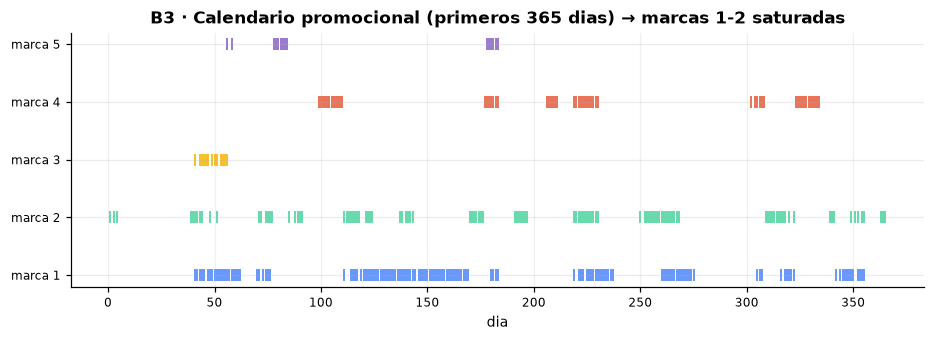

In [29]:
fig, ax = plt.subplots(figsize=(10, 3))
plots.plot_promo_calendar(df, ax=ax)
plt.show()

In [30]:
pvr = decisions.promo_vs_response(df)
display(pvr)
print(pvr.attrs["lectura"])

,index,frecuencia_promo,lift_share_con_promo,share_ingreso_pct,diagnostico
0,1,0.3438,1.08,7.6,"SOBRE-PROMOCIONADA (baja respuesta, alta inver..."
1,2,0.3156,1.39,26.3,alineada
2,3,0.0428,1.86,7.3,"SUB-PROMOCIONADA (alta respuesta, baja inversion)"
3,4,0.1179,1.16,23.0,alineada
4,5,0.0359,1.66,35.8,"SUB-PROMOCIONADA (alta respuesta, baja inversion)"


Hipotesis de arbitraje: reasignar dias de promocion de las marcas 1-2 hacia 3 y 5. El optimizador (P2) cuantifica el margen liberado.


**Consecuencia:** el presupuesto promocional observado es un total de días-promoción a
**reasignar**, no a aumentar. P2 decide ese calendario con los lifts de A5 como respuesta.

### B4 · `x_ijt` — heterogeneidad entre clientes

In [31]:
dfs = data.add_paid_price_and_spend(df)
clients = decisions.client_profile(dfs)
display(clients.head())

het = decisions.heterogeneity_summary(dfs)
display(het)
print(het.attrs["lectura"])

,id,visitas,compras,primer_dia,ultimo_dia,genero,estado_civil,edad,nivel_educacion,ingreso_anual,ocupacion,tasa_compra,gasto_total,ticket_medio
0,200000001,101,9,1,727,0,0,47,1,110866,1,0.0891,33.96,3.77
1,200000002,87,11,6,729,1,1,52,2,159052,2,0.1264,41.74,3.79
2,200000003,97,10,5,724,0,0,28,0,113212,1,0.1031,32.27,3.23
3,200000004,85,11,2,725,0,0,37,1,119602,0,0.1294,32.96,3.00
4,200000005,111,13,7,729,0,0,49,1,121466,1,0.1171,54.97,4.23


,visitas,compras,tasa_compra,gasto_total
count,500.000,500.000,500.000,500.000
mean,117.386,29.276,0.238,165.513
std,26.681,30.675,0.157,204.892
min,72.000,6.000,0.046,17.750
25%,103.000,15.000,0.133,66.380
50%,114.000,21.000,0.184,107.600
75%,125.000,34.000,0.307,181.540
max,358.000,327.000,0.922,1859.200


La tasa de compra va de 0.046 a 0.922 con mediana 0.184. Esa dispersion es la razon de existir del problema de targeting.


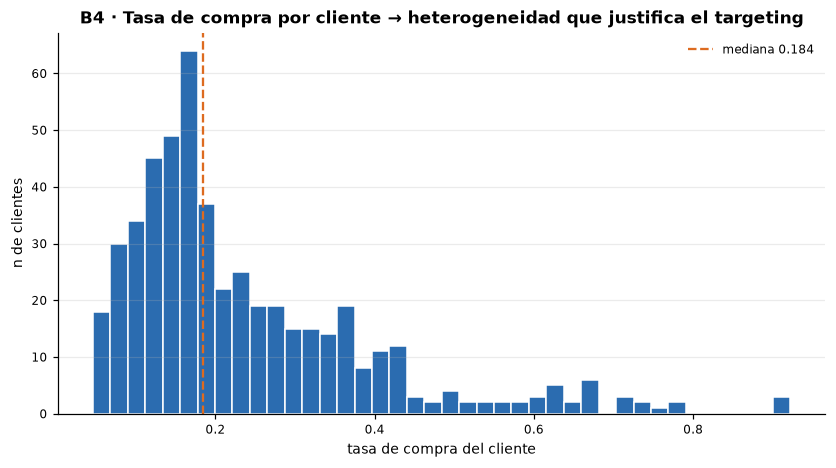

In [32]:
fig, ax = plt.subplots()
plots.plot_client_heterogeneity(clients, ax=ax)
plt.show()

**Consecuencia:** la tasa de compra va de **4.6% a 92.2%** con mediana 18.4%. Esa dispersión es
la razón de existir del problema de targeting: si todos los clientes fueran iguales, `x_ijt` no
tendría nada que decidir.

### B5 · `x_ijt` — concentración de valor

,top_pct_clientes,n_clientes,ingreso,share_ingreso_pct
0,10,50,30654.93,37.0
1,20,100,43628.80,52.7
2,30,150,52668.20,63.6
3,50,250,65898.19,79.6


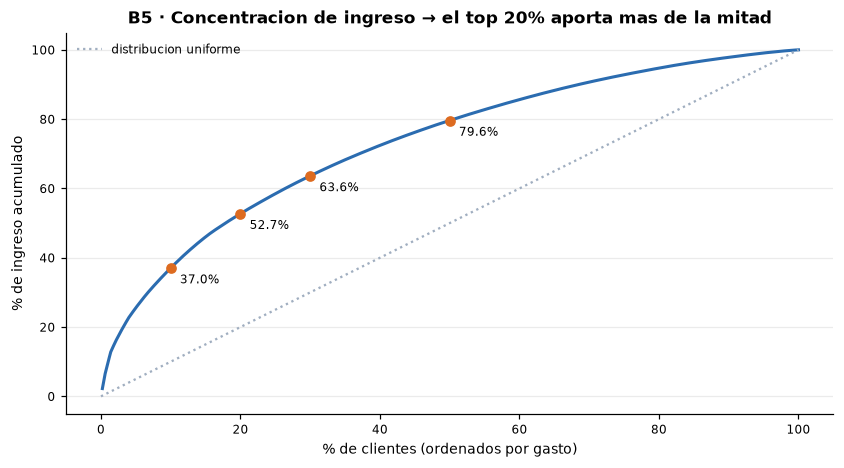

In [33]:
conc = decisions.pareto_concentration(dfs)
display(conc)

curve = decisions.pareto_curve(dfs)
fig, ax = plt.subplots()
plots.plot_pareto(curve, conc, ax=ax)
plt.show()

**Consecuencia:** el top 10% de clientes concentra el **37.0%** del ingreso y el top 20% el
**52.7%**. Contactar bien a 100 clientes cubre más de la mitad del valor: la restricción de
presupuesto R2 no es limitante si el targeting es correcto.

### B6 · `x_ijt` — el baseline que el modelo debe superar

,top_pct_clientes,n_clientes,tasa_compra_del_grupo,lift_vs_base,share_ingreso_pct
0,10,50,0.6050,2.43,33.7
1,20,100,0.4937,1.98,47.7
2,30,150,0.4312,1.73,62.0
3,50,250,0.3479,1.40,77.6


tasa base: 0.2494
Ordenar por tasa historica da lift x2.43 en el decil superior sin usar ningun modelo. M1 debe superarlo.


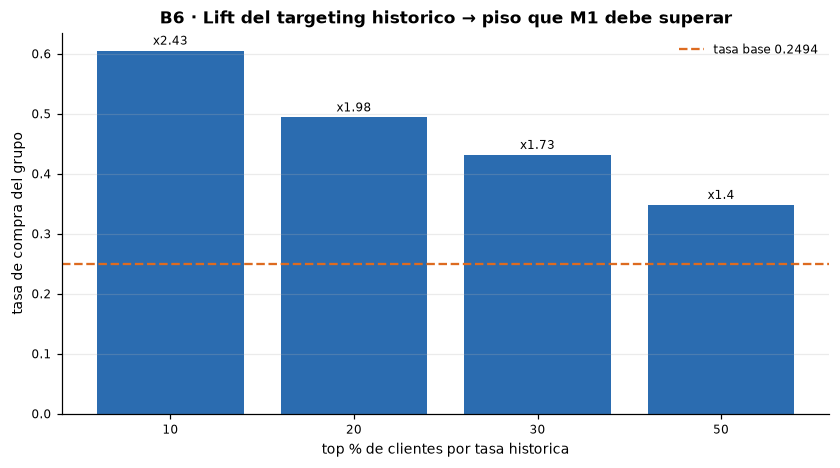

In [34]:
baseline = decisions.targeting_baseline_lift(dfs)
display(baseline)
print("tasa base:", baseline.attrs["tasa_base"])
print(baseline.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_targeting_baseline(baseline, ax=ax)
plt.show()

**Consecuencia:** ordenar clientes por su tasa de compra histórica da **lift ×2.43** en el decil
superior **sin usar ningún modelo**. Ese es el piso de desempeño de M1: un modelo que no lo
supere no justifica su existencia, y el valor de P1 se mide contra esta política, no contra el azar.

---
## 4 · Bloque C — Cotas de las restricciones

Parametrizar el MILP con evidencia donde sea posible, y declarar el supuesto donde no lo sea.

In [35]:
# C4 · R8 capacidad / inventario
cap = constraints.capacity_bounds(df)
display(cap)
print(cap.attrs["lectura"])

,marca,unidades_totales,unidades_por_dia_media,unidades_por_dia_p95,unidades_por_dia_max
0,1,4717,6.46,31.1,125
1,2,12828,17.57,62.0,149
2,3,2994,4.10,23.0,47
3,4,8877,12.16,40.0,79
4,5,11198,15.34,46.0,99


La media acota la capacidad en regimen; el p95 y el maximo acotan el pico. Cap_jt debe fijarse sobre el pico, no sobre la media.


In [36]:
# C5 · R3-R4 fatiga de contacto y escala operativa
fat = constraints.fatigue_bounds(df)
display(fat)
print(fat.attrs["lectura"])
display(constraints.visit_interval_profile(df))

,metrica,media,min,max
0,visitas por cliente (horizonte completo),117.4,72,358
1,visitas por dia,80.4,6,179
2,clientes distintos por dia,80.4,6,179


Con 117 visitas por cliente en 730 dias, el cliente aparece cada ~6 dias. F_i debe fijarse muy por debajo de esa frecuencia para no saturar.


,estadistico,dias_entre_visitas
0,count,58193.00
1,mean,6.20
2,std,3.72
3,min,1.00
4,25%,3.00
5,50%,6.00
6,75%,8.00
7,90%,11.00
8,max,41.00


In [37]:
# C1 · R5 presupuesto de días-promoción
budget = constraints.promo_budget_bounds(df)
display(budget)
print(budget.attrs["lectura"])

,marca,dias_en_promo,frecuencia_promo,n_bloques_promo,duracion_media_bloque,horizonte_dias,T_j_observado
0,1,235,0.3219,44,5.3,730,235
1,2,222,0.3041,51,4.4,730,222
2,3,29,0.0397,9,3.2,730,29
3,4,80,0.1096,15,5.3,730,80
4,5,24,0.0329,8,3.0,730,24


T_j se fija a partir de lo observado. El total de dias-promocion del horizonte (590) es el presupuesto a reasignar, no a aumentar.


In [38]:
# C2 · R6 piso de margen: la brecha honesta
constraints.margin_floor_gap()

,restriccion,parametro_requerido,disponible_en_el_dato,tratamiento
0,R6 piso de margen,"c_j (costo unitario), rho (margen minimo)",No,Parametrizar como supuesto de margen bruto por...
1,R2 presupuesto,"a (costo de contacto), d_j (costo de promo), B",No,Input de negocio; el umbral de decision de P1 ...
2,R7 arquitectura de marcas,Ordenamiento de precios exigido,"Parcial (medias ordenadas, rangos solapados)",Restriccion activable; se reporta el costo de ...


In [39]:
# Vista consolidada: ¿qué restricción se apoya en evidencia y cuál en supuesto?
constraints.constraint_parameter_summary(df)

,restriccion,fuente,parametrizada_con
0,R3 una oferta por cliente y periodo,estructura del problema,factible por construccion
1,R4 fatiga de contacto (F_i),evidencia,117 visitas/cliente observadas
2,R5 dias de promocion (T_j),evidencia,590 dias-promo observados
3,R6 piso de margen,SUPUESTO,c_j y rho no estan en el dato
4,R7 arquitectura de marcas,decision de modelado,rangos de precio solapados
5,R8 capacidad (Cap_jt),evidencia,pico diario hasta 149 unidades


**Consecuencia:** R4, R5 y R8 quedan acotadas por evidencia observada. R6 y R2 dependen de
parámetros que no están en el dato y se tratan como supuestos con sensibilidad. R7 es una
decisión de modelado. Esa separación es lo que delimita el alcance honesto de la solución.

---
## 5 · Bloque D — Demografía y segmentación (M0)

In [40]:
display(segments.demographic_profile(dfs))
segments.categorical_breakdown(dfs)

,variable,n_niveles,tipo,media,min,p50,max
0,genero,2,categorica/ordinal,0.39,0.0,0.0,1.0
1,estado_civil,2,categorica/ordinal,0.39,0.0,0.0,1.0
2,edad,56,continua,38.68,18.0,36.0,75.0
3,nivel_educacion,4,categorica/ordinal,1.10,0.0,1.0,3.0
4,ingreso_anual,499,continua,121520.16,38247.0,117804.5,309364.0
5,ocupacion,3,categorica/ordinal,0.77,0.0,1.0,2.0


,variable,nivel,clientes,pct_clientes
0,genero,0,306,61.2
1,genero,1,194,38.8
2,estado_civil,0,304,60.8
3,estado_civil,1,196,39.2
4,nivel_educacion,0 - Basico,75,15.0
5,nivel_educacion,1 - Medio,314,62.8
6,nivel_educacion,2 - Superior,99,19.8
7,nivel_educacion,3 - Posgrado,12,2.4
8,ocupacion,0 - Desempleado/otro,184,36.8
9,ocupacion,1 - Empleado,248,49.6


In [41]:
segments.purchase_rate_by_demographic(df)

,variable,nivel,visitas,tasa_compra,lift_vs_base
0,genero,0,36044,0.2610,1.05
1,genero,1,22649,0.2309,0.93
2,estado_civil,0,35620,0.2527,1.01
3,estado_civil,1,23073,0.2444,0.98
4,nivel_educacion,0 - Basico,8462,0.2085,0.84
5,nivel_educacion,1 - Medio,37161,0.2461,0.99
6,nivel_educacion,2 - Superior,11716,0.2975,1.19
7,nivel_educacion,3 - Posgrado,1354,0.1809,0.73
8,ocupacion,0 - Desempleado/otro,21032,0.2019,0.81
9,ocupacion,1 - Empleado,29882,0.2814,1.13


,variable,tasa_min,tasa_max,amplitud,ratio_max_min
0,nivel_educacion,0.1809,0.2975,0.1166,1.64
1,ocupacion,0.2019,0.2814,0.0795,1.39
2,genero,0.2309,0.2610,0.0301,1.13
3,estado_civil,0.2444,0.2527,0.0083,1.03


La mayor amplitud demografica es 0.1166, frente a 0.8760 de amplitud entre clientes individuales. La demografia segmenta pero no predice: el poder predictivo esta en el comportamiento y el contexto comercial.


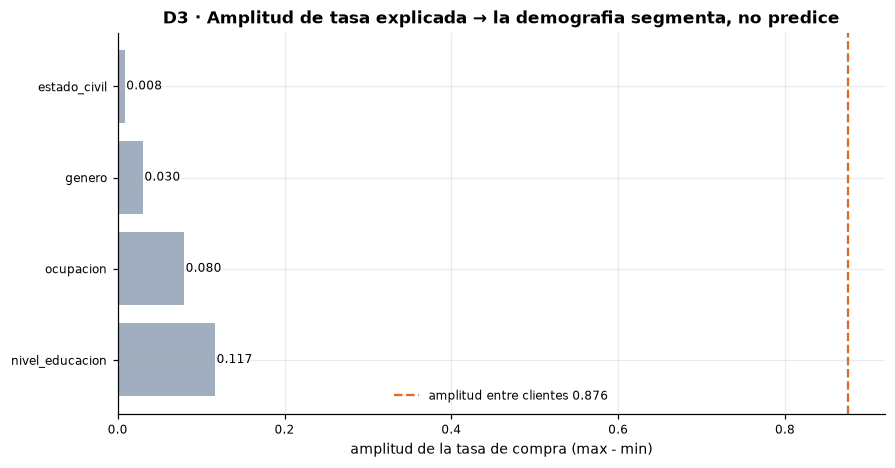

In [42]:
spread = segments.demographic_spread(dfs)
display(spread)
print(spread.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_demographic_spread(spread, spread.attrs["amplitud_entre_clientes"], ax=ax)
plt.show()

In [43]:
segments.continuous_demographic_bins(df)

,variable,bin,visitas,tasa_compra
0,edad,"(17.999, 27.0]",12124,0.1906
1,edad,"(27.0, 34.0]",12948,0.2383
2,edad,"(34.0, 40.0]",12257,0.2661
3,edad,"(40.0, 49.0]",10058,0.2338
4,edad,"(49.0, 75.0]",11306,0.3210
5,ingreso_anual,"(38246.999, 88849.0]",11759,0.1986
6,ingreso_anual,"(88849.0, 110190.0]",11750,0.2346
7,ingreso_anual,"(110190.0, 124597.0]",11741,0.2611
8,ingreso_anual,"(124597.0, 147967.0]",11850,0.2436
9,ingreso_anual,"(147967.0, 309364.0]",11593,0.3099


**Consecuencia — D3, y es una conclusión de diseño, no un detalle:** la mayor amplitud de tasa
de compra que explica una variable demográfica es ~0.12, frente a **0.876** de amplitud entre
clientes individuales. **La demografía segmenta pero no predice.**

Por lo tanto: la demografía alimenta el clustering M0 y la acción comercial (las campañas se
diseñan por segmento), mientras que el poder predictivo de M1 debe venir del **comportamiento
histórico y del contexto comercial** (precio, promoción), no del perfil.

In [44]:
# Matriz de entrada de M0: demografía a nivel cliente, lista para estandarizar y clusterizar
X_seg = segments.segmentation_matrix(dfs)
print(X_seg.shape)
X_seg.head()

(500, 6)


,genero,estado_civil,edad,nivel_educacion,ingreso_anual,ocupacion
id,,,,,,
200000001,0,0,47,1,110866,1
200000002,1,1,52,2,159052,2
200000003,0,0,28,0,113212,1
200000004,0,0,37,1,119602,0
200000005,0,0,49,1,121466,1


El comportamiento se mantiene **aparte** a propósito: clusterizar sobre comportamiento y luego
explicar el comportamiento por cluster sería circular. Se usa solo para perfilar los segmentos
después de ajustarlos.

In [45]:
segments.behaviour_by_client_for_validation(dfs).head()

,visitas,compras,tasa_compra,gasto_total,ticket_medio
id,,,,,
200000001,101,9,0.0891,33.96,3.77
200000002,87,11,0.1264,41.74,3.79
200000003,97,10,0.1031,32.27,3.23
200000004,85,11,0.1294,32.96,3.00
200000005,111,13,0.1171,54.97,4.23


---
## 6 · Dinámica temporal y anomalías

Las secciones 2–5 recorren la matriz del brief de problema. Esta recorre los dos puntos de la
**Fase 1 del brief de metodología** que esa matriz no cubre: la *dinámica temporal* de la demanda
y las *anomalías* del dato.

El primer punto tiene una trampa, y es la razón de que esta sección exista en lugar de ser tres
gráficos más: con 730 días plegados en 7 o en 12 posiciones **siempre** aparecen celdas que
superan su error estándar. Por eso aquí un veredicto de estacionalidad exige además que el patrón
**se repita en los dos años** del panel. Esa segunda prueba invierte la conclusión.

### 6.1 · Estacionalidad semanal y mensual

,dia_del_ciclo,visitas,compras,tasa_compra,tasa_anio_1,tasa_anio_2,desvio_vs_global,error_estandar,supera_ruido
0,1,9018,2345,0.2600,0.2504,0.2706,0.0106,0.0046,True
1,2,8524,2020,0.2370,0.2425,0.2318,-0.0124,0.0047,True
2,3,8530,2072,0.2429,0.2430,0.2428,-0.0065,0.0047,False
3,4,8128,2097,0.2580,0.2512,0.2665,0.0086,0.0048,False
4,5,8229,2038,0.2477,0.2370,0.2592,-0.0017,0.0048,False
5,6,8128,2116,0.2603,0.2508,0.2712,0.0109,0.0048,True
6,7,8136,1950,0.2397,0.2181,0.2648,-0.0097,0.0048,True


4 de 7 posiciones se desvian mas de 2 errores estandar y la amplitud es 0.0234 sobre una tasa global de 0.2494. Pero los perfiles de los dos anios del panel correlacionan +0.096: el patron no se repite, asi que no es estacionalidad. El trafico por posicion varia un 4.0%, asi que tampoco es un efecto de exposicion.


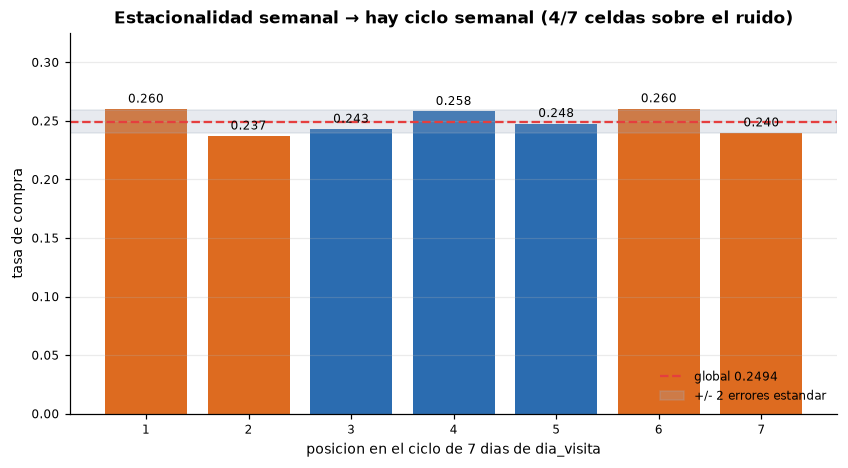

In [46]:
sem = dynamics.weekly_seasonality(df)
display(sem)
print(sem.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_weekly_seasonality(sem, float(df[cfg.TARGET_INCIDENCE].mean()), ax=ax)
plt.show()

In [47]:
mes = dynamics.monthly_seasonality(df)
display(mes)
print(mes.attrs["lectura"])

,mes_del_ciclo,visitas,compras,tasa_compra,tasa_anio_1,tasa_anio_2,desvio_vs_global,error_estandar,supera_ruido
0,1,5946,1201,0.2020,0.1447,0.2513,-0.0474,0.0056,True
1,2,5015,1116,0.2225,0.1836,0.2667,-0.0269,0.0061,True
2,3,5084,1179,0.2319,0.2343,0.2291,-0.0175,0.0061,True
3,4,5055,1341,0.2653,0.2829,0.2424,0.0159,0.0061,True
4,5,5186,1455,0.2806,0.2715,0.2909,0.0312,0.0060,True
5,6,4887,1369,0.2801,0.2717,0.2896,0.0307,0.0062,True
6,7,4932,1148,0.2328,0.2294,0.2365,-0.0166,0.0062,True
7,8,4543,1166,0.2567,0.2444,0.2714,0.0073,0.0064,False
8,9,4649,1206,0.2594,0.2714,0.2469,0.0100,0.0063,False
9,10,4522,1184,0.2618,0.2448,0.2801,0.0124,0.0064,False


8 de 12 posiciones superan el ruido, con pico en la 5 (0.2806) y valle en la 1 (0.2020) -- amplitud 0.0786, tres veces la del ciclo semanal. La correlacion entre los perfiles de los dos anios es +0.113: el patron no se repite, asi que no es estacionalidad. El valle de la posicion 1 es el arranque del panel (ver warmup_profile), no un mes flojo.


**Consecuencia: no hay estacionalidad, y la prueba de réplica es la que lo dice.**

| | Amplitud | Celdas sobre el ruido | Correlación entre los dos años |
|---|---|---|---|
| Ciclo de 7 días | 0.0234 | 4 de 7 | **+0.096** |
| Ciclo de 12 bloques | 0.0786 | 8 de 12 | **+0.113** |

Leído solo con el error estándar, el dato diría que hay estacionalidad semanal *y* mensual —
12 de 19 celdas se desvían más de dos errores estándar. Pero los perfiles del año 1 y del año 2
no se parecen (correlaciones de 0.10 y 0.11, cuando un ciclo real daría una correlación alta).
Lo que se desvía no se repite, así que no es un ciclo: es ruido de plegar 730 días en pocas
posiciones y probarlas todas.

Dos consecuencias concretas: **no se crea ninguna feature de día de la semana ni de mes
calendario**, y **P2 puede reasignar días de promoción sin restricción estacional** — no hay
temporada que respetar. Queda una pista que sí importa: el valle de la posición 1 (0.2020 frente
a 0.2806 del pico) no es un mes flojo, es el arranque del panel. Eso se mide a continuación.

### 6.2 · El régimen de arranque y la tendencia

,bloque,dia_inicial,dia_final,visitas,tasa_compra,pct_sin_historial,umbral,en_warmup
0,1,1,30,2750,0.1447,0.8822,0.2455,True
1,2,31,60,2664,0.1836,0.8367,0.2452,True
2,3,61,90,2727,0.2343,0.7734,0.2454,True
3,4,91,120,2856,0.2829,0.7304,0.2458,False
4,5,121,150,2766,0.2715,0.6992,0.2456,False
5,6,151,180,2584,0.2717,0.7446,0.2450,False
6,7,181,210,2611,0.2294,0.7442,0.2451,False
7,8,211,240,2480,0.2444,0.7754,0.2446,False


Los primeros 3 bloques (hasta el dia 90) estan por debajo de la referencia de train (0.2623): tasa 0.1874 frente a 0.2594 despues. En el bloque 1 el 88.2% de las visitas no tiene historial de compra, y esa proporcion cae bloque a bloque. No es estacionalidad ni tendencia: es el panel llenandose.


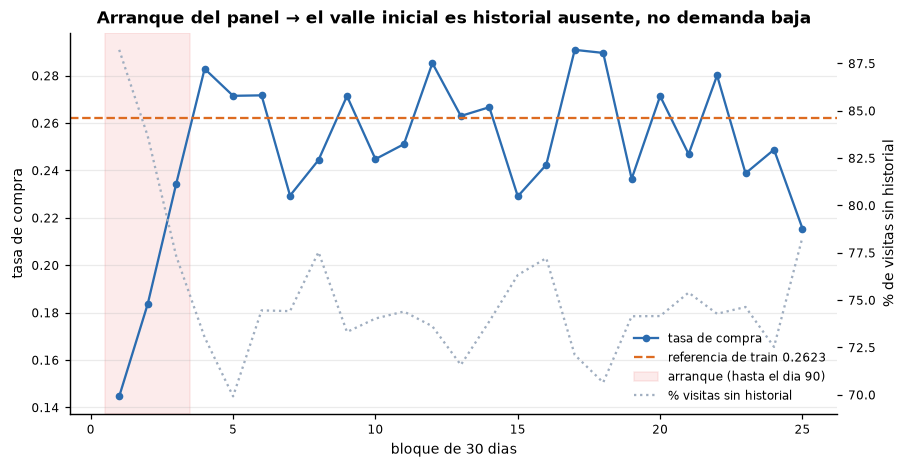

In [48]:
warm = dynamics.warmup_profile(df)
display(warm.head(8))
print(warm.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_warmup(warm, ax=ax)
plt.show()

**Consecuencia:** los primeros **3 bloques (hasta el día 90)** son otro régimen: tasa de compra
**0.1874** frente a **0.2594** después, y en el bloque 1 el **88.2%** de las visitas no tiene
historial de compra. No es estacionalidad ni tendencia — es el panel llenándose, y la caída de
esa proporción bloque a bloque lo confirma.

La referencia que define el corte se calcula **solo sobre train** (bloques 4 en adelante hasta el
día 550), así que decidir dónde termina el arranque no mira el test.

Qué se hace con esos 90 días: **entran al entrenamiento** —son compras reales— pero lo que debe
explicarlos es el **indicador de ausencia de historial** que la Fase 2 ya construye sin imputar
(control E7), no un parámetro temporal. Y las métricas de M1 se reportan también excluyéndolos,
porque un modelo que acierta en el arranque por el motivo equivocado acierta por una razón que no
se repetirá.

,bloque,dia_inicial,dia_final,visitas,tasa_compra,tendencia_completa,tendencia_post_warmup
19,20,571,600,2063,0.2714,0.2584,0.2532
20,21,601,630,2276,0.2469,0.2596,0.2524
21,22,631,660,2181,0.2801,0.2609,0.2515
22,23,661,690,2307,0.2388,0.2622,0.2507
23,24,691,720,2046,0.2488,0.2635,0.2499
24,25,721,730,789,0.2155,0.2648,0.2490


Sobre los 25 bloques completos la pendiente es +0.001281 (t=+1.40), pero esa recta esta arrastrada por el arranque. Desde el bloque 4 la pendiente es -0.000840 por bloque de 30 dias (error estandar 0.000724, t=-1.16, R2=0.0630): sin tendencia distinguible del ruido. Es la condicion que vuelve comparables train y test.


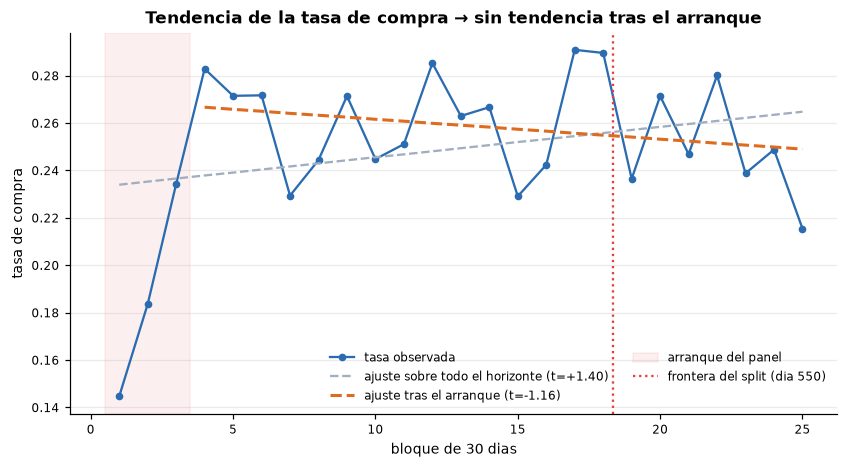

In [49]:
tend = dynamics.purchase_rate_trend(df)
display(tend.tail(6))
print(tend.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_rate_trend(tend, ax=ax)
plt.show()

In [50]:
resumen_temporal = dynamics.temporal_dynamics_summary(df)
display(resumen_temporal)
print(resumen_temporal.attrs["lectura"])

,pregunta,medida,veredicto,consecuencia
0,estacionalidad semanal,amplitud 0.0234; 4/7 celdas sobre el ruido; co...,no,no se crea feature de dia de la semana: el pat...
1,estacionalidad mensual,amplitud 0.0786; 8/12 celdas sobre el ruido; c...,no,P2 puede reasignar dias de promocion sin restr...
2,regimen de arranque del panel,3 bloques hasta el dia 90; tasa 0.1874 vs 0.25...,si,los primeros 90 dias son otro regimen; entran ...
3,tendencia de la tasa de compra,pendiente -0.000840 por bloque tras el arranqu...,no,el split temporal es comparable; semana y mes ...


Lo que parecia estacionalidad semanal y mensual no se repite entre los dos anios del panel: la unica dinamica temporal real son los primeros 90 dias de arranque. Despues de ellos la tasa de compra es plana, y eso es exactamente lo que el split temporal del dia 550 necesita para ser valido.


**Consecuencia — esta es la que llega hasta la Fase 4.** Ajustando una recta sobre los 25 bloques
la pendiente sale **+0.00128 por bloque (t=+1.40)**, pero esa recta está arrastrada por el
arranque. Desde el bloque 4 la pendiente es **−0.00084 (t=−1.16, R²=0.06)**: plana.

Que no haya tendencia es exactamente la condición que vuelve comparables train y test, y cierra
una pregunta que la Fase 2 dejó abierta: las features `semana` y `mes` son índices de tendencia
cuyos valores de test caen fuera del rango de train (98% y 88% de las filas). Si no hay señal
temporal que extrapolar, **extrapolarlas es riesgo sin beneficio**: la Fase 4 las evalúa con la
métrica en la mano y, salvo que aporten, se quitan.

### 6.3 · Anomalías

In [51]:
coh = anomalies.coherence_anomalies(df)
display(coh)
print(coh.attrs["lectura"])
assert coh.attrs["coherente"], "Hay filas que contradicen el contrato de datos"

,caso,es_posible,filas,pct,decision
0,incidencia=1 y cantidad=0,no,0,0.0,nada que corregir
1,incidencia=1 y id_marca=0,no,0,0.0,nada que corregir
2,incidencia=0 y cantidad>0,no,0,0.0,nada que corregir
3,incidencia=0 y id_marca>0,no,0,0.0,nada que corregir
4,id_marca=0 y cantidad>0,no,0,0.0,nada que corregir
5,id_marca>0 y cantidad=0,no,0,0.0,nada que corregir


Las seis combinaciones imposibles suman 0 filas sobre 58,693. Las tres columnas de resultado son coherentes entre si, asi que el universo condicional de M2 y M3 se define solo con incidencia_compra.


,cantidad,compras,clientes,unidades,ingreso,pct_compras,pct_unidades,pct_ingreso,pct_compras_acum
0,1,3542,440,3542,8262.42,24.20,8.72,9.98,24.20
1,2,3800,494,7600,16096.68,25.96,18.71,19.45,50.16
2,3,4241,488,12723,25176.60,28.97,31.33,30.42,79.13
3,4,1165,335,4660,9167.48,7.96,11.47,11.08,87.09
4,5,921,281,4605,9049.35,6.29,11.34,10.93,93.38
5,6,355,148,2130,4039.02,2.43,5.24,4.88,95.81
6,7,200,97,1400,2754.71,1.37,3.45,3.33,97.18
7,8,133,51,1064,2207.36,0.91,2.62,2.67,98.09
8,9,106,49,954,1945.98,0.72,2.35,2.35,98.81
9,10,81,38,810,1596.10,0.55,1.99,1.93,99.36


Maximo 15 unidades, media 2.77, mediana 2, p99 10. La cola de cantidad >= 6 es el 6.62% de las compras pero el 18.42% de las unidades, repartida en 180 clientes distintos: es comportamiento de cliente mayorista, no error de captura.


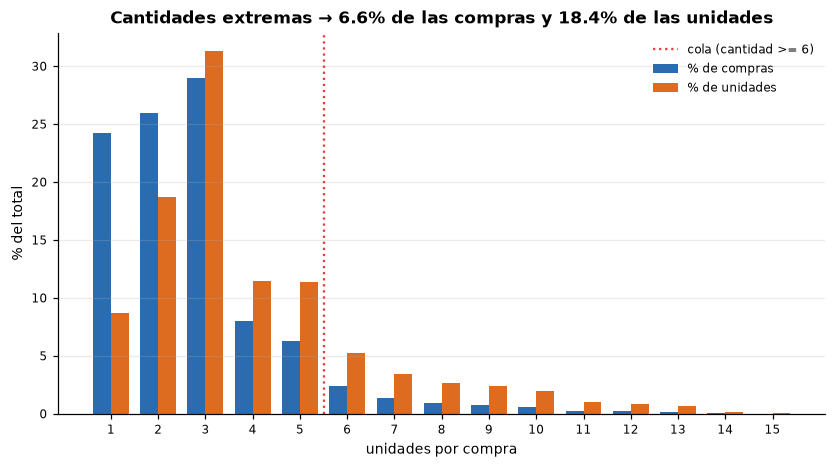

In [52]:
qty = anomalies.quantity_outliers(df)
display(qty)
print(qty.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_quantity_tail(qty, ax=ax)
plt.show()

In [53]:
atip = anomalies.atypical_clients(df)
display(atip.head(10))
print(atip.attrs["lectura"])

,id,visitas,compras,tasa_compra,unidades,gasto,z_tasa,z_visitas,z_gasto,atipico,motivo
246,200000247,347,320,0.9222,676,1786.48,4.36,8.61,7.92,True,tasa de compra
186,200000187,358,327,0.9134,702,1859.20,4.30,9.03,8.27,True,tasa de compra
40,200000041,353,322,0.9122,674,1781.05,4.29,8.84,7.89,True,tasa de compra
257,200000258,102,80,0.7843,177,313.24,3.48,-0.58,0.72,True,tasa de compra
344,200000345,178,137,0.7697,217,576.21,3.38,2.27,2.01,True,tasa de compra
197,200000198,108,82,0.7593,184,324.78,3.32,-0.35,0.78,True,tasa de compra
37,200000038,117,86,0.7350,129,323.25,3.16,-0.01,0.77,True,tasa de compra
90,200000091,172,125,0.7267,212,563.66,3.11,2.05,1.95,True,tasa de compra
392,200000393,179,129,0.7207,217,576.72,3.07,2.31,2.01,True,tasa de compra
51,200000052,110,79,0.7182,182,319.59,3.06,-0.28,0.75,True,tasa de compra


14 clientes de 500 superan 3.0 sigmas en tasa, visitas o gasto, y concentran el 16.43% del ingreso. Excluirlos moveria la tasa global de 0.2494 a 0.2255 (-0.0239). No se excluyen: son clientes reales y el optimizador los querra exactamente a ellos.


In [54]:
resumen_anomalias = anomalies.anomaly_summary(df)
display(resumen_anomalias)
print(resumen_anomalias.attrs["lectura"])

,anomalia,hallazgo,decision
0,incidencia=1 con cantidad=0 (y las otras 5 inc...,0 filas,no hay nada que filtrar; el target de M1 se us...
1,cantidades extremas (maximo 15),cola >= 6 = 6.62% de las compras y 18.42% de l...,no se truncan; M3 se evalua con MAE ademas de ...
2,clientes con comportamiento atipico,"14 clientes sobre 3.0 sigmas, 16.43% del ingre...",se conservan; la generalizacion a clientes nue...


Ninguna anomalia se corrige borrando filas. Las tres cambian como se evalua el modelo, no el dato que lo entrena.


**Consecuencia: ninguna de las tres anomalías se corrige borrando filas. Las tres cambian cómo se
evalúa el modelo, no el dato que lo entrena.**

| Anomalía | Hallazgo | Decisión |
|---|---|---|
| `incidencia_compra = 1` con `cantidad = 0` | **0 filas**, y las otras cinco combinaciones imposibles también en 0 | el target de M1 se usa tal cual; el universo condicional de M2/M3 se define solo con `incidencia_compra` |
| Cantidades extremas (máximo **15**) | la cola de ≥6 unidades es el **6.62%** de las compras pero el **18.42%** de las unidades, repartida en **180 clientes** | no se truncan: es comportamiento mayorista, no error de captura. M3 se evalúa con **MAE además de RMSE** para que la cola no dicte el ajuste |
| Clientes atípicos | **14 clientes** sobre 3σ concentran el **16.43%** del ingreso; tres compran en ~92% de sus visitas | se conservan — el optimizador querrá exactamente a esos clientes. Excluirlos movería la tasa global de 0.2494 a 0.2255, así que el riesgo se mide donde se ve: **`GroupKFold` por `id`** |

El criterio común: una anomalía se **describe y se decide**, nunca se filtra en silencio. Un
filtro aplicado aquí y olvidado en el notebook de modelado es la forma más barata de que dos
notebooks dejen de coincidir.

---
## 7 · Procesamiento y variables derivadas

Las cinco familias de la §3 del brief de problema. Toda feature de historial se construye
**estrictamente hacia el pasado** (control E6).

In [55]:
feat = features.build_features(dfs)
print("columnas antes:", dfs.shape[1], "→ después:", feat.shape[1])
features.feature_summary(feat)

columnas antes: 26 → después: 68


,familia,feature,pct_nulos,media,min,max
0,precio,precio_min_dia,0.0,1.389,1.100,1.590
1,precio,precio_medio_dia,0.0,1.999,1.872,2.102
2,precio,precio_max_dia,0.0,2.655,2.160,2.800
3,precio,rango_precios_dia,0.0,1.266,0.800,1.590
4,precio,precio_relativo_1,0.0,0.696,0.561,0.781
5,precio,precio_relativo_2,0.0,0.890,0.669,0.993
6,precio,precio_relativo_3,0.0,1.004,0.938,1.076
7,precio,precio_relativo_4,0.0,1.081,0.924,1.176
8,precio,precio_relativo_5,0.0,1.328,1.114,1.427
9,precio,desviacion_precio_1,0.0,0.002,-0.208,0.144


Los nulos en las features de historial son **esperados y correctos**: en las primeras visitas de
un cliente no existe historial. No se imputan con la media; el modelo debe recibir esa ausencia
como información.

### 7.1 · Verificación de fuga de datos (E6)

Tres pruebas concretas sobre la matriz construida, en lugar de una declaración de intención.

In [56]:
leak = features.verify_no_leakage(feat)
display(leak)
assert leak.attrs["sin_fuga"], "Fuga detectada en las features de historial"
print("Sin fuga: las features de historial no contienen información de la visita actual.")

,verificacion,features_evaluadas,violaciones,detalle,estado
0,Primera visita sin historial (features = 0 o NaN),13,0,ninguna,OK
1,n_compras_previas excluye la compra de la fila...,1,0,cumsum() - fila actual,OK
2,lealtad_marca no reacciona a la compra actual,5,0,53 primeras visitas con compra evaluadas,OK


Sin fuga: las features de historial no contienen información de la visita actual.


In [57]:
# Matriz admisible para M1: excluye targets, resultados post-visita, tamanio_ciudad y claves
X = features.feature_matrix(feat)
y = feat[cfg.TARGET_INCIDENCE]

print("matriz de features M1:", X.shape)
for forbidden in [cfg.TARGET_BRAND, cfg.TARGET_QUANTITY, *cfg.EXCLUDED_COLS, "gasto", "precio_pagado"]:
    assert forbidden not in X.columns, forbidden
print("Verificado: ninguna columna post-resultado ni excluida entró en la matriz.")

matriz de features M1: (58693, 60)
Verificado: ninguna columna post-resultado ni excluida entró en la matriz.


**Consecuencia:** `id_marca` y `cantidad` son **resultados** de la visita, no condiciones previas.
Si entraran como features de M1, las métricas saldrían casi perfectas y el modelo sería inútil
en producción. La función `feature_matrix()` los excluye por construcción, no por disciplina del
analista.

---
## 8 · Estrategia de validación (E8, E9)

In [58]:
split = data.split_composition(feat)
display(split)

train, test = data.temporal_split(feat)
print(f"train: días {train[cfg.KEY_TIME].min()}-{train[cfg.KEY_TIME].max()}  |  "
      f"test: días {test[cfg.KEY_TIME].min()}-{test[cfg.KEY_TIME].max()}")

,split,filas,clientes,dia_min,dia_max,tasa_compra
0,train,45497,500,1,550,0.2498
1,test,13196,500,551,730,0.2480


train: días 1-550  |  test: días 551-730


**Consecuencia:** corte temporal en el día **550**. Ambos lados conservan los 500 clientes y la
misma tasa base (0.2498 vs 0.2480), así que el split no introduce sesgo de composición.

Un `train_test_split` aleatorio sería **inválido**: con ~117 visitas por cliente repartiría
visitas del mismo cliente entre train y test e inflaría todas las métricas. En paralelo se usará
`GroupKFold` por `id` para medir generalización a clientes nuevos — con solo 500 clientes, ese es
el riesgo real de sobreajuste.

---
## 9 · Auditoría de alineamiento

Evaluación automática de los 13 controles de tratamiento (§3) y de la matriz de
trazabilidad (§2) del brief de alineamiento, más el checklist de la Fase 1 del brief de
metodología.

In [59]:
aud = audit.treatment_audit(
    df,
    feature_cols=list(X.columns),
    featured_df=feat,
    notebook_runs_clean=True,   # este notebook corre de extremo a extremo
)
display(aud)
print("bloqueantes fallados:", aud.attrs["bloqueantes_fallados"])
print("pendientes:", aud.attrs["pendientes"])
assert aud.attrs["bloqueantes_fallados"] == 0, "Hay controles bloqueantes fallados"

,control,verificacion,severidad,estado,evidencia
0,E1,tamanio_ciudad excluida,Bloqueante,OK,Verificado contra la matriz de features
1,E2,id_marca fuera de las features de M1,Bloqueante,OK,"Es resultado de la visita, no condicion previa"
2,E3,cantidad fuera de las features de M1,Bloqueante,OK,"Es resultado de la visita, no condicion previa"
3,E4,ultima_marca_comprada validada como lag,Bloqueante,OK,Coincidencia con shift(1) por cliente: 1.0
4,E5,ultima_cantidad_comprada reinterpretada,Alta,OK,Binaria (0/1): el diccionario la nombra mal; e...
5,E6,Features de historial retrospectivas,Bloqueante,OK,3 pruebas sobre la matriz construida: primera ...
6,E7,ultima_marca_comprada=0 como categoria,Alta,OK,"44,133 filas sin historial; no se imputan"
7,E8,"Split temporal, no aleatorio",Bloqueante,OK,Corte en dia_visita <= 550
8,E9,Split sin sesgo de composicion,Alta,OK,"train 45,497 @ 0.2498 / test 13,196 @ 0.248"
9,E10,Escalado y codificacion solo en train,Bloqueante,PENDIENTE,Pasar prepared=preprocess.prepare() para ejecu...


bloqueantes fallados: 0
pendientes: 1


**E10** queda **pendiente** por diseño: el escalado y la codificación ajustados solo en train
no se pueden verificar antes de que exista el `Pipeline`. Es el único control que este notebook
no puede cerrar, y lo cierra la Fase 2 en
[`02_procesamiento.ipynb`](02_procesamiento.ipynb) con cuatro pruebas ejecutadas.

In [60]:
# Fase 1 del brief de metodología: cada ítem y la función que produce su evidencia.
# El estado se resuelve importando la función, no declarándola.
fase1 = audit.metodologia_fase1_matrix()
display(fase1)
print(fase1.attrs["lectura"])
assert fase1.attrs["completa"], "Hay ítems de la Fase 1 sin evidencia en el código"

,item,requisito_del_brief,funciones,seccion_notebook,estado
0,1,"Distribucion de la variable objetivo, global y...",eda.objective.purchase_rate / eda.objective.pu...,2 (A1) y 5 (D3),OK
1,2,"Perfil de los 500 clientes: edad, genero, esta...",eda.segments.demographic_profile / eda.segment...,"5 (D1, D2)",OK
2,3,Dinamica temporal: estacionalidad semanal/mens...,eda.dynamics.weekly_seasonality / eda.dynamics...,6.1,OK
3,4,Estructura de precios: trayectoria de los 5 pr...,eda.decisions.daily_price_series / eda.decisio...,3 (B2),OK
4,5,Efecto bruto de promocion: tasa de compra con ...,eda.objective.incidence_by_n_promos / eda.obje...,2 (A3),OK
5,6,Anomalias: visitas con incidencia_compra = 1 y...,eda.anomalies.coherence_anomalies / eda.anomal...,6.2,OK


6 de 6 items de la Fase 1 del brief de metodologia tienen su evidencia resuelta en el codigo.


Los seis ítems resuelven. Dos matices que la tabla deja explícitos: el ítem 1 (distribución del
objetivo por segmento demográfico) se responde entre A1 y D3, y el ítem 3 (frecuencia de visita)
se lee de `constraints.visit_interval_profile`, ya calculado en el bloque C — no se recalcula
aquí para que no existan dos cifras de lo mismo.

In [61]:
# Trazabilidad: cada elemento del problema y la función que produce su evidencia
audit.traceability_matrix()

,id,elemento_del_problema,funcion_que_lo_produce
0,A1,pi - tasa base y estabilidad,eda.objective.purchase_rate / purchase_rate_by...
1,A2,pi - sensibilidad al precio,eda.objective.incidence_by_price_quintile
2,A3,pi - sensibilidad a promocion,eda.objective.incidence_by_n_promos
3,A4,q - share de marca condicional,eda.objective.brand_share
4,A5,q - sustitucion y canibalizacion,eda.objective.promo_lift_on_brand_share / bran...
5,A6,lambda - cantidad dado compra,eda.objective.quantity_distribution / quantity...
6,A7,m - ingreso y brecha de costos,eda.objective.revenue_by_brand / missing_busin...
7,B1,y_jtk - escalera de precios,eda.decisions.price_ladder
8,B2,y_jtk - dinamica de precios,eda.decisions.daily_price_series / price_corre...
9,B3,z_jt - calendario promocional,eda.decisions.promo_calendar_profile / promo_v...


---
## 10 · Síntesis: qué entrega este EDA al problema de optimización

| Elemento | Estado | Evidencia |
|---|---|---|
| **π** sensible a precio | estimable | caída relativa del 32% entre quintiles extremos |
| **π** sensible a promoción | estimable | 21.8% → 29.0% por nº de promos; +0.6 a +6.9 pp por marca |
| **π** sin estacionalidad ni tendencia | verificado | réplica entre años +0.10 / +0.11; pendiente t=−1.16 |
| **q** con sustitución | estimable | lifts ×1.08 a ×1.86 + matriz de cambio de marca |
| **λ** distribución de conteo | estimable | media 2.77, asimétrica, cola a 15 |
| **m** margen unitario | **no estimable** | faltan costos → supuesto + sensibilidad |
| `y_jtk` espacio de precio | **acotado** | menú discreto de 21–44 puntos por marca |
| `z_jt` calendario | **acotado** | días-promo observados por marca |
| `x_ijt` targeting | **justificado** | dispersión 4.6%–92.2%, top 20% = 52.7% del ingreso |
| R4, R5, R8 | acotadas por evidencia | frecuencia de visita, días-promo, unidades/día |
| R6, R2 | supuesto declarado | `c_j`, `a`, `d_j`, `B` no están en el dato |
| R7 | decisión de modelado | rangos de precio solapados |

### Las cuatro conclusiones que cambian la solución

1. **La promoción está mal asignada hoy, y la marca 5 es el arbitraje.** Las marcas 1 y 2
   absorben un tercio de los días de promoción y responden ×1.08 y ×1.39 en share; las marcas 3 y
   5 casi no se promocionan y responden ×1.86 y ×1.66. Pero medido sobre la **incidencia**, que es
   lo que crea compras en lugar de redistribuirlas, la marca 5 suma **+6.90 pp** con 24 días de
   promoción y la marca 3 no se mueve (z=0.7). La reasignación tiene un destino concreto, y es una
   decisión de P2, no de un clasificador.

2. **La demografía segmenta pero no predice.** Amplitud demográfica ~0.12 frente a 0.876 entre
   clientes. El poder predictivo está en el comportamiento histórico y el contexto comercial; la
   demografía va al clustering y a la acción comercial.

3. **El baseline no es trivial.** Ordenar por tasa histórica ya da lift ×2.43. M1 tiene que
   superar eso, y la captura de valor se mide contra esa política — no contra la selección aleatoria.

4. **No hay señal temporal que modelar, salvo los primeros 90 días.** Lo que parecía
   estacionalidad semanal y mensual no se repite entre los dos años del panel (correlaciones de
   0.10 y 0.11); tras el arranque la tasa de compra es plana (t=−1.16). Eso valida el split del
   día 550 y deja a `semana` y `mes` sin señal que justifique su extrapolación en test.

### Siguiente paso

`02_modelado.ipynb`: segmentación M0, y los tres modelos M1/M2/M3 sobre el split temporal del
día 550, con PR-AUC como métrica principal, `GroupKFold` por cliente, SHAP para explicabilidad,
y el umbral de decisión derivado del costo de contacto — no fijado en 0.5.